# Estimate rates of change and differences between predictions

A fitted curve often leaves a more specific question unanswered: where is the response increasing, and how much does the predicted response change between two conditions?

We will estimate a smooth’s derivative and use the linear-predictor matrix to calculate contrasts with uncertainty.

## Fit a smooth relationship

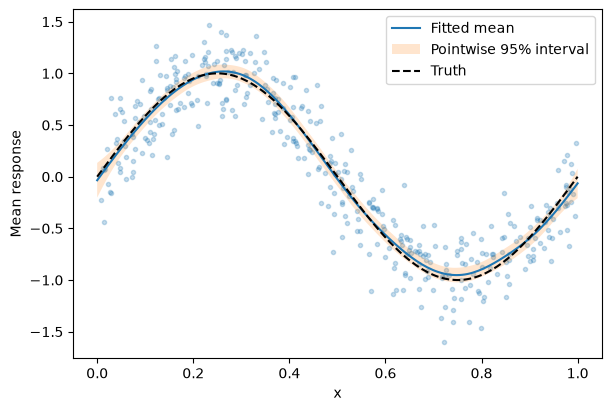

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nampy.gam import GAM

rng = np.random.default_rng(103)
x = np.sort(rng.uniform(0, 1, 400))
data = pd.DataFrame({"x": x, "y": np.sin(2*np.pi*x) + rng.normal(0, .25, len(x))})
model = GAM(formula="y ~ s(x, bs='ps', k=16)", smoothing_method="reml", optimize_smoothing=True).fit(data)
grid = pd.DataFrame({"x": np.linspace(0, 1, 180)})
mean, se = model.predict(grid, type="link", return_se=True)
figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
axis.scatter(data.x, data.y, s=9, alpha=.25)
axis.plot(grid.x, mean, label="Fitted mean")
axis.fill_between(grid.x, mean-1.96*se, mean+1.96*se, alpha=.2, label="Pointwise 95% interval")
axis.plot(grid.x, np.sin(2*np.pi*grid.x), "k--", label="Truth")
axis.set(xlabel="x", ylabel="Mean response")
axis.legend()
plt.show()
plt.close(figure)

## Estimate its derivative

The first derivative measures change in the fitted link-scale mean per unit change in x. A zero reference distinguishes increasing and decreasing regions.

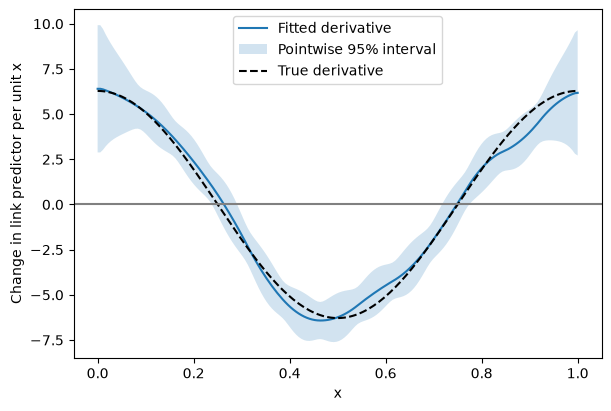

In [2]:
derivative = model.derivative(grid, smooth_number=1, deriv=1)
value = np.asarray(derivative.derivative).reshape(-1)
se_derivative = np.asarray(derivative.se).reshape(-1)
figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
axis.plot(grid.x, value, label="Fitted derivative")
axis.fill_between(grid.x, value-1.96*se_derivative, value+1.96*se_derivative, alpha=.2, label="Pointwise 95% interval")
axis.plot(grid.x, 2*np.pi*np.cos(2*np.pi*grid.x), "k--", label="True derivative")
axis.axhline(0, color="grey")
axis.set(xlabel="x", ylabel="Change in link predictor per unit x")
axis.legend()
plt.show()
plt.close(figure)

## Compare two predictor settings

We compare each grid point with x=0.25. The reference is fixed before inspecting results. For prediction-matrix rows $X_a$ and $X_b$,

$$C=X_a-X_b,\qquad \widehat{\Delta}=C\widehat{\beta},\qquad \operatorname{Var}(\widehat{\Delta})=CVC^\mathsf{T}.$$

## Calculate uncertainty for the contrast

Using the complete coefficient covariance preserves the covariance between both predictions. Adding separate prediction variances would lose it.

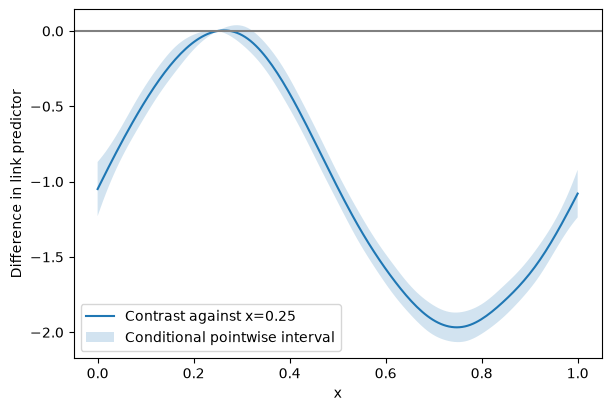

In [3]:
reference = pd.DataFrame({"x": np.repeat(.25, len(grid))})
C = model.lpmatrix(grid) - model.lpmatrix(reference)
result = model.fit_result()
contrast = C @ result.coef_full
V = model.vcov()
contrast_se = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", C, V, C), 0))
figure, axis = plt.subplots(figsize=(6, 4), constrained_layout=True)
axis.plot(grid.x, contrast, label="Contrast against x=0.25")
axis.fill_between(grid.x, contrast-1.96*contrast_se, contrast+1.96*contrast_se, alpha=.2, label="Conditional pointwise interval")
axis.axhline(0, color="grey")
axis.set(xlabel="x", ylabel="Difference in link predictor")
axis.legend()
plt.show()
plt.close(figure)

## Account for smoothing-parameter uncertainty where supported

We only report an adjusted interval when the fit actually provides an unconditional covariance. Otherwise this example reports the conditional interval alone.

In [4]:
intervals = {"Conditional": contrast_se}
if result.cov_unconditional is not None:
    V_adjusted = model.vcov(unconditional=True)
    intervals["Smoothing-adjusted"] = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", C, V_adjusted, C), 0))
rows = [20, 90, 150]
pd.DataFrame([{"x": float(grid.x.iloc[row]), "Covariance": name,
               "Contrast": contrast[row], "Lower": contrast[row]-1.96*std[row],
               "Upper": contrast[row]+1.96*std[row]}
              for name, std in intervals.items() for row in rows]).style.hide(axis="index").format({"x":"{:.2f}","Contrast":"{:.3f}","Lower":"{:.3f}","Upper":"{:.3f}"})

x,Covariance,Contrast,Lower,Upper
0.11,Conditional,-0.403,-0.500,-0.305
0.50,Conditional,-1.056,-1.152,-0.960
0.84,Conditional,-1.818,-1.921,-1.716
0.11,Smoothing-adjusted,-0.403,-0.501,-0.304
0.50,Smoothing-adjusted,-1.056,-1.153,-0.959
0.84,Smoothing-adjusted,-1.818,-1.922,-1.715


These intervals describe uncertainty at each evaluated point. They do not provide simultaneous coverage for the entire curve.

The prediction-matrix contrast is on the linear-predictor scale. Include any difference in known offsets separately; for a nonlinear link, a response-scale contrast requires transforming the predictions and accounting for that transformation.

The conditional and smoothing-adjusted intervals are close in this fit. Their availability does not change the pointwise interpretation or turn them into simultaneous confidence bands.

A prediction contrast against a fixed reference is exactly zero at that reference by construction; this is not evidence of unusually precise estimation there. The displayed bands are pointwise: excluding zero at one location is not a simultaneous claim over the entire predictor range.